In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures


# Полиномиальная Регрессия
$$
y = 0.5x^3 - 3x^2 + 2x + noise
$$

In [2]:
n = 120
X = np.linspace(-4, 6, n).reshape(-1, 1)
noise = np.random.normal(0, 6, n)

In [4]:
y = 0.5*X.flatten()**3 - 3*X.flatten()**2 + 2*X.flatten() + noise

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)
len(X_train), len(X_test)

(90, 30)

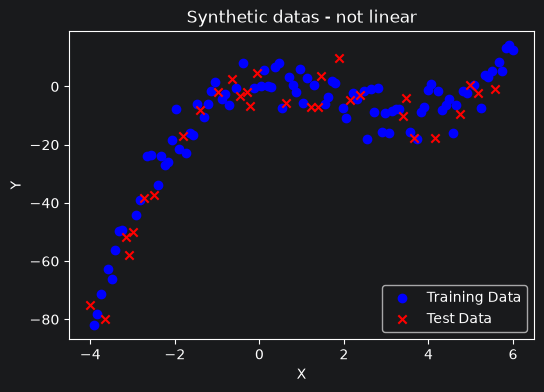

In [9]:
plt.figure(figsize = (6,4))
plt.scatter(X_train, y_train, color = 'blue', label = 'Training Data')
plt.scatter(X_test, y_test, color = 'red', label = 'Test Data', marker = 'x')
plt.title('Synthetic datas - not linear')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [10]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

y_pred_train_linear = lin_model.predict(X_train)
y_pred_test_linear = lin_model.predict(X_test)

r2_train_linear = r2_score(y_train, y_pred_train_linear)
r2_test_linear = r2_score(y_test, y_pred_test_linear)

rmse_train_linear = root_mean_squared_error(y_train, y_pred_train_linear)
rmse_test_linear = root_mean_squared_error(y_test, y_pred_test_linear)

print(f'''
Linear Regression model:
Train RMSE: {rmse_train_linear:.2f}, Test RMSE: {rmse_test_linear:.2f}
Train r2: {r2_train_linear:.2f}, Test r2: {r2_test_linear:.2f}
''')


Linear Regression model:
Train RMSE: 14.92, Test RMSE: 17.85
Train r2: 0.44, Test r2: 0.43



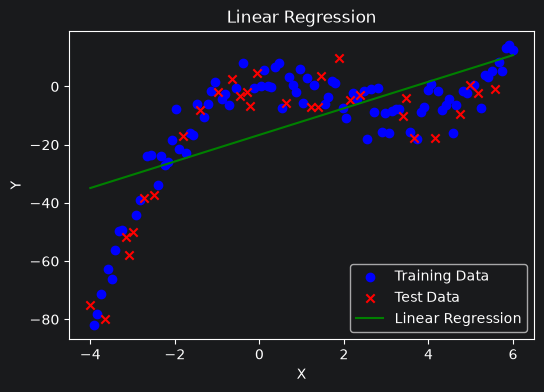

In [11]:
X_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_grid = lin_model.predict(X_grid)

plt.figure(figsize = (6,4))
plt.scatter(X_train, y_train, color = 'blue', label = 'Training Data')
plt.scatter(X_test, y_test, color = 'red', label = 'Test Data', marker = 'x')
plt.plot(X_grid, y_grid, color = 'green', label = 'Linear Regression')
plt.title('Linear Regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [13]:
poly_pipe = Pipeline(
    [
        ('poly', PolynomialFeatures(include_bias=False)),
        ('linear', LinearRegression())
    ]
)

param_grid = {
    'poly__degree': list(range(1, 11)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=poly_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_degree = grid_search.best_params_['poly__degree']
best_cv_rmse = -grid_search.best_score_
print(f'''
Polynomial Regression model Best Degree: {best_degree}
Cross Validation RMSE: {best_cv_rmse:.2f}:
''')


Polynomial Regression model Best Degree: 3
Cross Validation RMSE: 5.09:



In [14]:
rows = []

for d in range(1, 11):
    pipe = Pipeline([
        ('poly', PolynomialFeatures(include_bias=False, degree=d)),
        ('linear', LinearRegression())
    ])

    pipe.fit(X_train, y_train)
    y_tr = pipe.predict(X_train)
    y_tst = pipe.predict(X_test)

    rows.append({
        'degree': d,
        'train RMSE': root_mean_squared_error(y_train, y_tr),
        'test RMSE': root_mean_squared_error(y_test, y_tst),
        'train r2': r2_score(y_train, y_tr),
        'test r2': r2_score(y_test, y_tst),
    })

metrics_df = pd.DataFrame(rows).set_index('degree')
metrics_df

,train RMSE,test RMSE,train r2,test r2
degree,,,,
1,14.922354,17.853084,0.443017,0.428378
2,11.278532,11.242891,0.681820,0.773307
3,4.785441,6.360305,0.942719,0.927450
4,4.771360,6.255482,0.943056,0.929821
5,4.769280,6.233980,0.943105,0.930303
6,4.736927,6.513367,0.943874,0.923916
7,4.674849,6.987440,0.945336,0.912437
8,4.700624,7.048602,0.944731,0.910898
9,4.972908,6.808590,0.938143,0.916862


In [15]:
best_model = Pipeline([
        ('poly', PolynomialFeatures(include_bias=False, degree=best_degree)),
        ('linear', LinearRegression())
    ])

best_model.fit(X_train, y_train)
y_best_train = best_model.predict(X_train)
y_best_test = best_model.predict(X_test)

print(f"""
Polynomial Regression Model:
    Best Degree: {best_degree}
    Best Train RMSE: {root_mean_squared_error(y_train, y_best_train):.2f}
    Best Test RMSE: {root_mean_squared_error(y_test, y_best_test):.2f}
    Best Train R2 Score: {r2_score(y_train, y_best_train):.2f}
    Best Test R2 Score: {r2_score(y_test, y_best_test):.2f}
""")


Polynomial Regression Model:
    Best Degree: 3
    Best Train RMSE: 4.79
    Best Test RMSE: 6.36
    Best Train R2 Score: 0.94
    Best Test R2 Score: 0.93



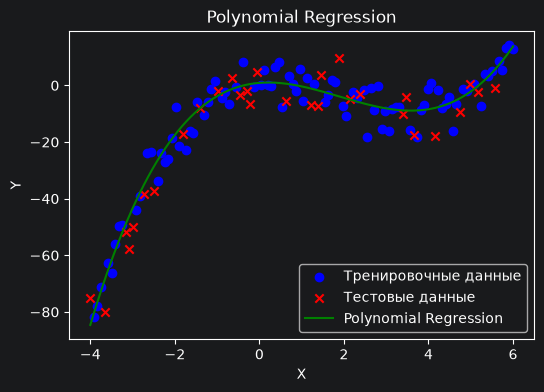

In [16]:
X_dense = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_dense_best = best_model.predict(X_grid)

plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color='blue', label='Тренировочные данные')
plt.scatter(X_test, y_test, color='red', label='Тестовые данные', marker='x')
plt.plot(X_dense, y_dense_best, color='green', label='Polynomial Regression')
plt.title('Polynomial Regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [23]:
def fit_metrics_for_degree(d):
    pipe = Pipeline([
    ("poly", PolynomialFeatures(degree=d,include_bias=False)),
    ("lin", LinearRegression())
])
    pipe.fit(X_train, y_train)
    ytr = pipe.predict(X_train)
    yte = pipe.predict(X_test)
    return  pipe, {
        "degree": d,
        "train_R2": r2_score(y_train, ytr),
        "test_R2": r2_score(y_test, yte),
        "train_rmse": root_mean_squared_error(y_train, ytr),
        "test_rmse": root_mean_squared_error(y_test, yte),
    }

model_low, m_low = fit_metrics_for_degree(1)
model_best, m_best = best_model, {
    "degree": best_degree,
    "train_R2": r2_score(y_train, best_model.predict(X_train)),
        "test_R2": r2_score(y_test, best_model.predict(X_test)),
        "train_rmse": root_mean_squared_error(y_train, best_model.predict(X_train)),
        "test_rmse": root_mean_squared_error(y_test, best_model.predict(X_test)),
}

model_high, m_high = fit_metrics_for_degree(11)
pd.DataFrame([m_low, m_best, m_high])

,degree,train_R2,test_R2,train_rmse,test_rmse
0,1,0.443017,0.428378,14.922354,17.853084
1,3,0.942719,0.927450,4.785441,6.360305
2,11,0.877087,0.883678,7.009954,8.053583


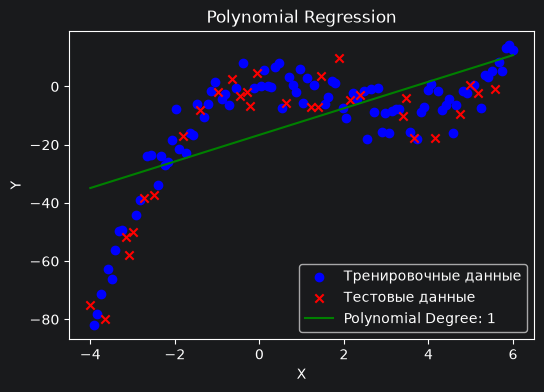

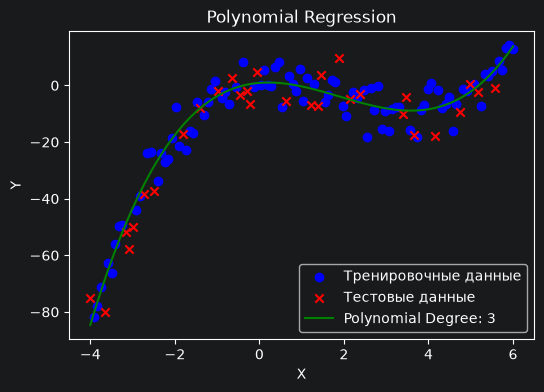

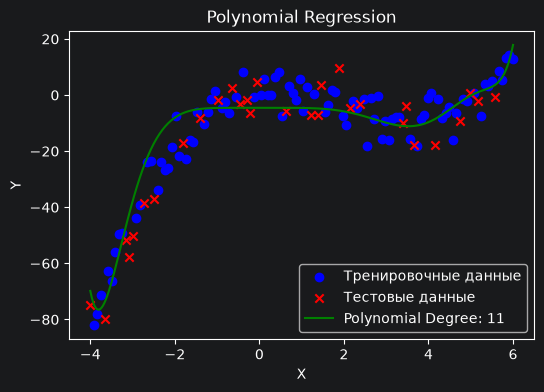

In [24]:
for d, model in [(1, model_low), [best_degree, model_best], (11, model_high)]:
    plt.figure(figsize=(6, 4))
    y_curve = model.predict(X_dense)
    plt.scatter(X_train, y_train, color='blue', label='Тренировочные данные')
    plt.scatter(X_test, y_test, color='red', label='Тестовые данные', marker='x')
    plt.plot(X_dense, y_curve, color='green', label=f'Polynomial Degree: {d}')
    plt.title('Polynomial Regression')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.legend()
    plt.show()